# Grouped Shared-Prefix Training Prototype

In [1]:
import importlib
import random
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, "kev")

import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon2025 as _grummon2025_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _issp_mod,
    _twin2k_mod,
    _grummon2025_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import (
    build_persona_dataset,
    load_split_qids,
)
from data.grummon2025 import load_grummon2025
from data.issp import load_issp_df, load_issp_eval
from data.twin2k import load_twin2k_df
from training import GroupedTrainer, free_gpu

## 1. Load & Build Persona Datasets

In [2]:
INCLUDE_COUNTRY = False
TEST10_SEED = 42

issp_qids = load_split_qids("splits/split.json")
issp_train_df = load_issp_df(qids=issp_qids["train"])
twin_df = load_twin2k_df()
train_df = pd.concat([issp_train_df, twin_df], ignore_index=True)

train_records_issp_twin2k_resp = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_resp"
)

issp_test10_qids = random.Random(TEST10_SEED).sample(sorted(issp_qids["test"]), 10)
issp_resp_valid_grouped = load_issp_eval(
    qids=issp_qids["valid"], attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid", valid=False
)
issp_resp_test_grouped = load_issp_eval(
    qids=issp_qids["test"], attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="test", valid=False
)
issp_resp_test10_grouped = load_issp_eval(
    qids=issp_test10_qids, attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="test_10", valid=True
)
grummon2025_grouped = load_grummon2025(
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False
)

eval_records = [issp_resp_test10_grouped, grummon2025_grouped]

print(
    f"Train records : {len(train_records_issp_twin2k_resp):,}\n"
    f"Eval sets     : "
    f"valid={len(issp_resp_valid_grouped['records']):,} ({len(issp_resp_valid_grouped['packed_views']):,} states), "
    f"test={len(issp_resp_test_grouped['records']):,} ({len(issp_resp_test_grouped['packed_views']):,} states), "
    f"test_10={len(issp_resp_test10_grouped['records']):,} ({len(issp_resp_test10_grouped['packed_views']):,} states), "
    f"grummon2025={len(grummon2025_grouped['records']):,} ({len(grummon2025_grouped['packed_views']):,} states)"
)

Loaded 1,737,940 records from train_records_resp_minNone_d98864c0.pkl
Loaded 64,201 records from valid_records_minNone_eaa9b07e.pkl
Loaded 92,992 records from test_records_minNone_6a10f9dc.pkl
Loaded 13,006 records from test_10_records_minNone_4228e0b9.pkl
Train records : 1,737,940
Eval sets     : valid=64,201 (14,236 states), test=92,992 (14,263 states), test_10=13,006 (8,026 states), grummon=33,798 (3,652 states)


## 2. Configure & Instantiate `GroupedTrainer`


In [3]:
resume = False
val_every = 50
# Choose model preset ("9b" or "0.8b"):
PRESET = "9b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped",
        weights_dtype="fp32",
        use_bf16=False,
        gradient_checkpointing=False,
        max_questions_per_group=64,
        max_chars_per_group=20_000,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = GroupedTrainer(
    train_records=train_records_issp_twin2k_resp,
    eval_records=eval_records,
    lora_rank=64,
    epochs=5,
    lr=5e-5,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    samples_per_epoch=None,
    resume=resume,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

,trainer_config
run_name,kev-9b-resp-issp+twin2k-grouped
base,Qwen/Qwen3.5-9B-Base
lora_rank,64
mode,lora_rank 64
weights_dtype,bf16
use_bf16,True
gradient_checkpointing,True
max_questions_per_group,96
max_chars_per_group,36000
groups_per_epoch,40162


## 3. Train

`trainer.train()` initializes the composed `TrainingPlotter` display, runs the grouped shared-prefix training loop, saves `best`/`last` checkpoints and lightweight `trainer_state.pt`, and automatically frees optimizer/scheduler/gradient buffers in `finally:`.

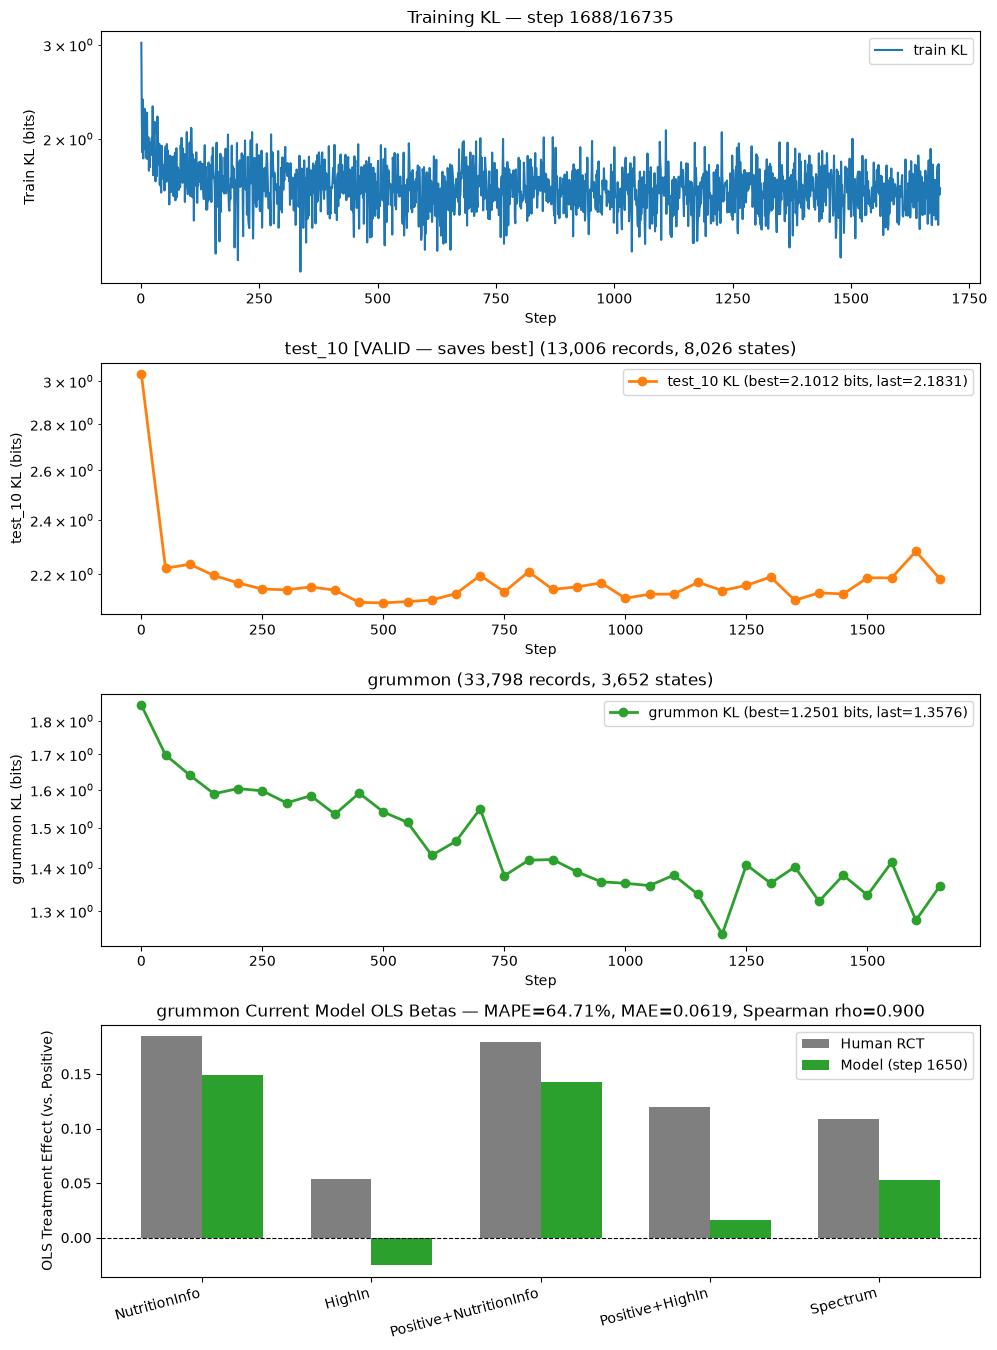

,epoch,step,train_kl,test_10_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,3.0347,1.8494,61.89,0.0691,0.0058,0.9000
1,1,50,1.6007,2.2212,1.6984,76.84,0.0892,0.0099,0.8000
2,1,100,1.5886,2.2357,1.6409,72.43,0.0765,0.0084,0.8000
3,1,150,1.8535,2.1956,1.5893,66.86,0.0670,0.0070,0.8000
4,1,200,1.6729,2.1696,1.6034,70.71,0.0718,0.0068,0.8000
5,1,250,1.6773,2.1482,1.5972,67.09,0.0658,0.0060,0.8000
6,1,300,1.7400,2.1457,1.5646,62.12,0.0579,0.0055,0.8000
7,1,350,1.5766,2.1556,1.5839,70.06,0.0678,0.0064,0.8000
8,1,400,1.4644,2.1447,1.5345,63.79,0.0600,0.0047,0.9000
9,1,450,1.3103,2.1029,1.5910,64.65,0.0638,0.0052,0.9000


,human,model,abs_diff
NutritionInfo,0.1844,0.1490,0.0355
HighIn,0.0541,-0.0252,0.0793
Positive+NutritionInfo,0.1788,0.1422,0.0367
Positive+HighIn,0.1194,0.0165,0.1029
Spectrum,0.1083,0.0531,0.0553


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


kev.cuda_graphs: capturing ('rows', 32, 160, 128) failed, it runs eagerly: OutOfMemoryError: CUDA out of memory. Tried to allocate 240.00 MiB. GPU 0 has a total capacity of 31.43 GiB of which 242.25 MiB is free. Process 1375 has 84.13 MiB memory in use. Including non-PyTorch memory, this process has 30.18 GiB memory in use. Of the allocated memory 24.05 GiB is allocated by PyTorch, with 1.06 GiB allocated in private pools (e.g., CUDA Graphs), and 4.57 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)
kev.cuda_graphs: capturing ('rows', 32, 96, 128) failed, it runs eagerly: OutOfMemoryError: CUDA out of memory. Tried to allocate 144.00 MiB. GPU 0 has a total capacity of 31.43 GiB of which 92.81 MiB is free. Process 1375 has 136.82 MiB memory in use. Incl

KeyboardInterrupt: 

In [4]:
plotter = trainer.train()

## 4. Optional: Probe VRAM directly on `trainer`

`trainer.probe_vram(grid)` reuses `trainer.train_one_step` with a zero-LR AdamW optimizer (and 2 micro-batches when `grad_accum_steps > 1`) inside `torch.random.fork_rng` so it measures exact steady-state peak VRAM without mutating model weights, RNG state, or creating empty plots.

In [ ]:
df_probe = trainer.probe_vram([
    (64, 24_000),
    (96, 36_000),
    (128, 48_000),
    (160, 60_000),
])
display(df_probe)

# You can also update grouping on the fly and recompute the schedule:
# trainer.set_grouping(max_questions_per_group=160, max_chars_per_group=60_000)